--- IKÄRYHMÄT ---
age_group
Alle 40       47
40 tai yli    35
Name: count, dtype: int64

--- RISTIINTAULUKOINTI: Sukupuoli vs Palkkatyytyväisyys ---
sat_salary   1   2   3  4  5
gender                      
1           32  12  12  7  0
2            1   7   7  3  1


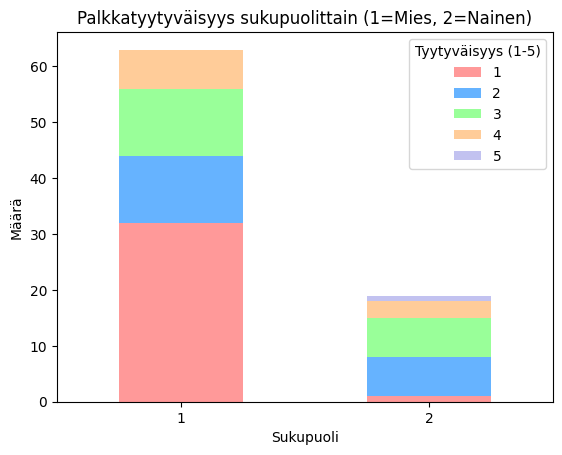

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

# 1. PANDAS: Ladataan data
df = pd.read_excel('WorkPlaceSatisfactionSurveyData.xlsx', sheet_name='Data')

# 2. NUMPY: Luokitellaan ikä (age) kahteen ryhmään Numpyn avulla.
# np.where toimii näin: jos ikä on alle 40, laitetaan 'Alle 40', muuten '40 tai yli'
df['age_group'] = np.where(df['age'] < 40, 'Alle 40', '40 tai yli')

# 3. PANDAS: Lasketaan ikäryhmien koot ja tehdään ristiintaulukointi sukupuolen kanssa
ika_kpl = df['age_group'].value_counts()
print("--- IKÄRYHMÄT ---")
print(ika_kpl)

# Ristiintaulukointi: Sukupuoli ja Palkkatyytyväisyys
print("\n--- RISTIINTAULUKOINTI: Sukupuoli vs Palkkatyytyväisyys ---")
crosstab_salary = pd.crosstab(df['gender'], df['sat_salary'])
print(crosstab_salary)

# 4. MATPLOTLIB: Piirretään graafi ristiintaulukoinnista
crosstab_salary.plot(kind='bar', stacked=True, color=['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0'])
plt.title('Palkkatyytyväisyys sukupuolittain (1=Mies, 2=Nainen)')
plt.xlabel('Sukupuoli')
plt.ylabel('Määrä')
plt.legend(title='Tyytyväisyys (1-5)')
plt.xticks(rotation=0)

# Näytetään graafi
plt.show()

--- SUKUPUOLI ---
            Kpl  Prosenttia
Mies (1)     63        76.8
Nainen (2)   19        23.2


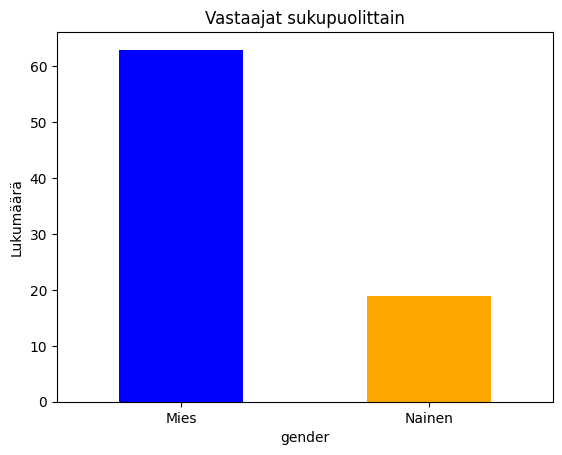

In [3]:
print("--- SUKUPUOLI ---")
sukupuoli_kpl = df['gender'].value_counts()
sukupuoli_pros = df['gender'].value_counts(normalize=True) * 100
# Huom: Datan koodistossa 1=mies, 2=nainen
sukupuoli_taulukko = pd.DataFrame({'Kpl': sukupuoli_kpl, 'Prosenttia': sukupuoli_pros.round(1)})
sukupuoli_taulukko.index = ['Mies (1)', 'Nainen (2)']
print(sukupuoli_taulukko)

sukupuoli_kpl.plot(kind='bar', color=['blue', 'orange'])
plt.title('Vastaajat sukupuolittain')
plt.xticks(ticks=[0, 1], labels=['Mies', 'Nainen'], rotation=0)
plt.ylabel('Lukumäärä')
plt.show()

=== SUKUPUOLI VS SAT-MUUTTUJAT ===

Ristiintaulukointi: Sukupuoli ja sat_management
sat_management  1   2   3   4  5
gender                          
1               7  15  23  15  3
2               0   1   7   8  3

Ristiintaulukointi: Sukupuoli ja sat_colleques
sat_colleques  2.0  3.0  4.0  5.0
gender                           
1                3    9   27   23
2                0    7    8    4

Ristiintaulukointi: Sukupuoli ja sat_workingEnvironment
sat_workingEnvironment  1  2   3   4  5
gender                                 
1                       9  7  27  15  5
2                       0  2   3   8  6

Ristiintaulukointi: Sukupuoli ja sat_salary
sat_salary   1   2   3  4  5
gender                      
1           32  12  12  7  0
2            1   7   7  3  1

Ristiintaulukointi: Sukupuoli ja sat_tasks
sat_tasks  1   2   3   4  5
gender                     
1          4  14  22  18  5
2          1   1   7   7  3

=== IKÄRYHMÄ VS SAT-MUUTTUJAT ===

Ristiintaulukointi: Ikäryhmä j

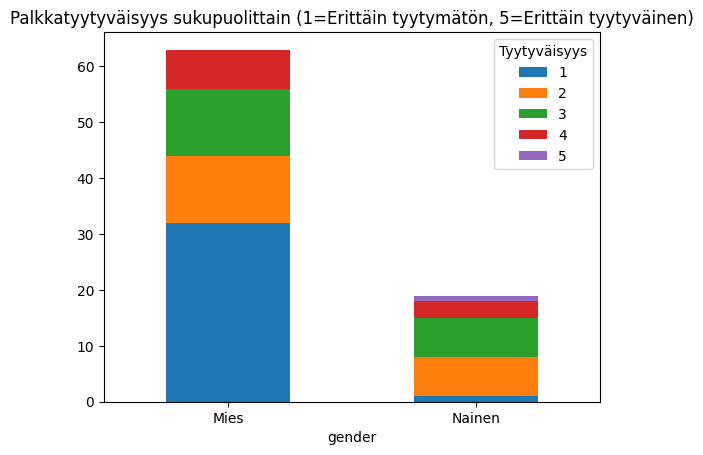

In [4]:
sat_muuttujat = ['sat_management', 'sat_colleques', 'sat_workingEnvironment', 'sat_salary', 'sat_tasks']

print("=== SUKUPUOLI VS SAT-MUUTTUJAT ===")
for sat in sat_muuttujat:
    crosstab_gender = pd.crosstab(df['gender'], df[sat])
    print(f"\nRistiintaulukointi: Sukupuoli ja {sat}")
    print(crosstab_gender)

print("\n=== IKÄRYHMÄ VS SAT-MUUTTUJAT ===")
for sat in sat_muuttujat:
    crosstab_age = pd.crosstab(df['age_group'], df[sat])
    print(f"\nRistiintaulukointi: Ikäryhmä ja {sat}")
    print(crosstab_age)

# Tehdään yksi graafi esimerkiksi Sukupuolen ja Palkkatyytyväisyyden välille esitystä varten:
crosstab_esimerkki = pd.crosstab(df['gender'], df['sat_salary'])
crosstab_esimerkki.plot(kind='bar', stacked=True)
plt.title('Palkkatyytyväisyys sukupuolittain (1=Erittäin tyytymätön, 5=Erittäin tyytyväinen)')
plt.xticks(ticks=[0, 1], labels=['Mies', 'Nainen'], rotation=0)
plt.legend(title='Tyytyväisyys')
plt.show()

In [5]:
# 1. Chi2-testi (Sukupuoli vs Palkkatyytyväisyys)
crosstab_chi2 = pd.crosstab(df['gender'], df['sat_salary'])
chi2, p_val_chi, dof, expected = stats.chi2_contingency(crosstab_chi2)
print("--- CHI2 TESTI (Sukupuoli vs Palkkatyytyväisyys) ---")
print(f"p-arvo: {p_val_chi:.3f}")

# 2. Keskiarvot ryhmittäin
print("\n--- PALKKATYYTYVÄISYYDEN KESKIARVO SUKUPUOLITTAIN ---")
mean_sat_by_gender = df.groupby('gender')['sat_salary'].mean().round(2)
print(mean_sat_by_gender)

# 3. T-testi (Palkkatyytyväisyys: Miehet vs Naiset)
sat_men = df[df['gender'] == 1]['sat_salary'].dropna()
sat_women = df[df['gender'] == 2]['sat_salary'].dropna()

t_stat, p_val_t = stats.ttest_ind(sat_men, sat_women)
print("\n--- T-TESTI (Palkkatyytyväisyysero sukupuolittain) ---")
print(f"p-arvo: {p_val_t:.3f}")

--- CHI2 TESTI (Sukupuoli vs Palkkatyytyväisyys) ---
p-arvo: 0.005

--- PALKKATYYTYVÄISYYDEN KESKIARVO SUKUPUOLITTAIN ---
gender
1    1.90
2    2.79
Name: sat_salary, dtype: float64

--- T-TESTI (Palkkatyytyväisyysero sukupuolittain) ---
p-arvo: 0.002
